# 02 Modeling (v2, merged dataset): P(success | age, Ivy League, degree level, batch)

Run this top to bottom yourself. Nothing here has been run on your real data.

**What changed from v1**
- Reads the merged sheet (original founders + the Kaggle YC founders). Put `founders_linkedin_filled_final_with_kaggle.xlsx` in the same folder as this notebook.
- Adds a `source` column (original or kaggle) and a coverage table by source.
- Fixes: the Fisher test now reports the odds ratio of *success* for Ivy vs other, the industry list is capped at 4 groups, and year axes use whole numbers.
- Optional switches in the config cell: drop weakly supported Kaggle statuses, and cluster standard errors by person instead of by company.

**Read this before interpreting the new rows.** The Kaggle founders have a status, a batch and an industry, but no education, grad year or age yet (the Profile Scraper has not been run on them). So they only add to Section 4 (YC batch). Sections 1 to 3 still use the same founders as before until their education is filled in.

**What each section answers (your professor's list)**
1. P(success | founder age)
2. P(success | went to an Ivy League school)
3. Do people with a master's (vs. bachelor's only) succeed more? (Section 4 also covers YC batch.)

**How success is defined**
- success = `acquired` or `public`; failure = `inactive`
- `active` and `unclear` companies are left out, because their outcome is not decided yet (censored)

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from scipy import stats

DATA_PATH = "founders_linkedin_filled_final_with_kaggle.xlsx"
ASSUMED_GRAD_AGE = 22                      # same assumption as your sheet (cell S1)
SUCCESS_STATUSES = {"acquired", "public"}
FAILURE_STATUSES = {"inactive"}
USE_SOURCES = ("original",)   # ("original",) = batch results from your original rows only; run once each and report both
DROP_LOW_CONFIDENCE = False   # True = ignore Kaggle statuses rated "low" or "none" (they rest on the YC badge alone)
CLUSTER_COL = "company_name"  # try "founder_id" to cluster by person (serial founders appear in several rows)            # try adding "active" to SUCCESS_STATUSES for a sensitivity check

BLUE, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
})

## 0. Load and build features

In [ ]:
raw = pd.read_excel(DATA_PATH, sheet_name=0)
raw.columns = [str(c).strip() for c in raw.columns]

df = raw.rename(columns={
    "fullName": "founder", "Verified Founding Year": "founding_year_verified",
    "Bachelor's Grad Year": "grad_year", "Published Age": "published_age",
    "Year Age Published": "year_age_published", "Basis": "basis", "Age Method": "age_method",
})
print(df.shape)
df.head(3)

(2047, 23)


,founder,company_name,industry,founding_year,batch,LIN_url,Unnamed: 6,LIN_url_source,link_check,founding_year_verified,...,Age at Founding,age_method,basis,Unnamed: 16,Assumed age at bachelor's grad,22,current_status,status_source,status_notes,status_confidence
0,Murtaza Ali,Symphony,Social Media,2024.0,F24,https://www.linkedin.com/in/-murtazaali,NaN,NaN,NaN,2024.0,...,NaN,Not found,Georgia Tech (ISE); no grad year found publicly,NaN,NaN,NaN,active,YC page,Voice AI sims for employee training,NaN
1,Shobhit Srivastava,Symphony,Social Media,2024.0,F24,https://www.linkedin.com/in/shobhit-srivastava,NaN,YC company page,Live - profile name matches (checked 9/23/26),2024.0,...,NaN,Not found,Georgia Tech (CS/AI); no grad year found publicly,NaN,NaN,NaN,active,YC page,Voice AI sims for employee training,NaN
2,Charlie Holtz,Melty,Social Network Media,2005.0,S24,https://www.linkedin.com/in/charlieholtz/,NaN,NaN,NaN,2024.0,...,NaN,Not found,Brown (cognitive neuroscience); no grad year f...,NaN,NaN,NaN,active,YC page,Rebranded as Conductor (same founders); Mac ap...,NaN


In [ ]:
# --- Age at founding (mirrors the formula in your sheet's column N) ---
age_published = df["published_age"] + (df["founding_year_verified"] - df["year_age_published"])
age_from_grad = df["founding_year_verified"] - df["grad_year"] + ASSUMED_GRAD_AGE
df["age"] = age_published.fillna(age_from_grad)

# --- Outcome ---
df["success"] = np.select(
    [df["current_status"].isin(SUCCESS_STATUSES), df["current_status"].isin(FAILURE_STATUSES)],
    [1.0, 0.0], default=np.nan)

# --- Which file the row came from, and a person id (serial founders appear more than once) ---
df["source"] = np.where(df["status_confidence"].notna(), "kaggle", "original") if "status_confidence" in df else "original"
slug = df["LIN_url"].astype(str).str.extract(r"linkedin\.com/in/([^/?#]+)", flags=re.I)[0].str.lower()
df["founder_id"] = slug.fillna(df["founder"].astype(str).str.lower().str.strip())
df.loc[~df["source"].isin(USE_SOURCES), "success"] = np.nan
if DROP_LOW_CONFIDENCE and "status_confidence" in df:
    weak = df["status_confidence"].fillna("").astype(str).str.startswith(("low", "none"))
    df.loc[weak, "success"] = np.nan
    print(f"Set success to missing for {int(weak.sum())} weakly supported Kaggle rows")

# --- Education flags, parsed from the free-text 'basis' column ---
basis = df["basis"].fillna("").astype(str)

IVY_RE      = re.compile(r"\b(Harvard|HBS|Yale|Princeton|Columbia|Cornell|Dartmouth|Brown(?: Univ(?:ersity)?| \()|UPenn|U Penn|Penn(?! State)|Wharton|University of Pennsylvania)\b")
NOT_IVY_RE  = re.compile(r"British Columbia|Columbia Basin|Columbia College Chicago|Columbia Southern|Penn State|Pennsylvania State|Penn Almanac|deferred \w+|Fulbright at \w+")
MASTERS_RE  = re.compile(r"[Mm]aster|\bMBA\b|\bMSc\b|\bMEng\b|\bMPhil\b|\bMFA\b|\bMPA\b|\bMPP\b|\bMS\b|\bM\.S\.")
PHD_RE      = re.compile(r"Ph\.?D|[Dd]octorate|\bDPhil\b")
DROPOUT_RE  = re.compile(r"[Dd]ropout|[Dd]ropped out|[Dd]id not graduate")
NO_EDU_RE   = re.compile(r"^\s*[Nn]o\b[^;]*\beducation")      # e.g. 'No education dates found'

df["edu_known"] = basis.ne("") & ~basis.map(lambda s: bool(NO_EDU_RE.search(s)))
df["ivy"]     = basis.map(lambda s: bool(IVY_RE.search(NOT_IVY_RE.sub("", s))))
df["masters"] = basis.map(lambda s: bool(MASTERS_RE.search(s)))
df["phd"]     = basis.map(lambda s: bool(PHD_RE.search(s)))
df["dropout"] = basis.map(lambda s: bool(DROPOUT_RE.search(s)))

# Manual fixes after you audit the matches below: put row numbers (the DataFrame index) here.
IVY_FORCE_TRUE, IVY_FORCE_FALSE = [], []
df.loc[IVY_FORCE_TRUE, "ivy"] = True
df.loc[IVY_FORCE_FALSE, "ivy"] = False

# Highest degree found (only defined where we actually know their education)
df["degree_level"] = np.select(
    [~df["edu_known"], df["phd"], df["masters"], df["dropout"]],
    [None, "phd", "masters", "dropout"], default="bachelors_only")
df.loc[~df["edu_known"], "degree_level"] = np.nan

# --- Controls ---
df["founding_year_c"] = df["founding_year_verified"] - df["founding_year_verified"].mean()
top_ind = df["industry"].astype(str).str.strip().value_counts().head(4).index
df["industry_grp"] = np.where(df["industry"].astype(str).str.strip().isin(top_ind),
                              df["industry"].astype(str).str.strip(), "Other")

# --- YC batch -> season + year ---
parts = df["batch"].astype(str).str.extract(r"^([A-Za-z]+)\s*(\d{2,4})$")
df["batch_season"] = parts[0]
yr = pd.to_numeric(parts[1], errors="coerce")
df["batch_year"] = np.where(yr < 100, 2000 + yr, yr)

In [ ]:
coverage = pd.Series({
    "founder rows": len(df),
    "with a known outcome (success/failure)": df["success"].notna().sum(),
    "with a computed age": df["age"].notna().sum(),
    "with a computed age AND known outcome": (df["age"].notna() & df["success"].notna()).sum(),
    "with education info in 'basis'": df["edu_known"].sum(),
    "with education info AND known outcome": (df["edu_known"] & df["success"].notna()).sum(),
    "flagged Ivy League": df["ivy"].sum(),
    "flagged master's": df["masters"].sum(),
    "flagged PhD": df["phd"].sum(),
}, name="rows")
coverage.to_frame()

,rows
founder rows,2047
with a known outcome (success/failure),1095
with a computed age,302
with a computed age AND known outcome,160
with education info in 'basis',538
with education info AND known outcome,289
flagged Ivy League,58
flagged master's,75
flagged PhD,25


### Coverage by source
Shows what the Kaggle rows add. Expect them to have outcomes but no age or education yet.

In [ ]:
by_src = df.groupby("source").agg(
    rows=("founder", "size"),
    unique_people=("founder_id", "nunique"),
    known_outcome=("success", lambda s: int(s.notna().sum())),
    with_age=("age", lambda s: int(s.notna().sum())),
    with_education=("edu_known", "sum"),
)
display(by_src)
print("Success rate among resolved rows, by source:")
display(df.dropna(subset=["success"]).groupby("source")["success"].agg(rate="mean", n="count").round(3))
if "status_confidence" in df:
    print("Kaggle rows by how well their status is supported:")
    display(df.loc[df["source"] == "kaggle", "status_confidence"].value_counts().to_frame("rows"))

,rows,unique_people,known_outcome,with_age,with_education
source,,,,,
kaggle,553,551,136,0,0
original,1494,1463,959,302,538


Success rate among resolved rows, by source:


,rate,n
source,,
kaggle,0.831,136
original,0.547,959


Kaggle rows by how well their status is supported:


,rows
status_confidence,
"low (YC badge only, no news check)",291
higher (news or company site),169
"medium (YC badge, no second source)",74
none,19


### Audit the education flags first
The flags come from keyword matching on free text, so check them before trusting any result. Look for false positives (e.g. a school mentioned but never attended) and add those row numbers to `IVY_FORCE_FALSE` in the cell above, then re-run from there.

In [ ]:
pd.set_option("display.max_colwidth", 110); pd.set_option("display.max_rows", 200)
print("IVY matches:");      display(df.loc[df["ivy"], ["founder", "basis"]])

IVY matches:


,founder,basis
2,Charlie Holtz,Brown (cognitive neuroscience); no grad year found
7,Scott Cara,Duke BS 2010–2014; HBS MBA 2019–2021
20,Sam Crombie,Dartmouth BA Computer Science 2019–2023
21,Faiyam Rahman,Duke BS Math; Cornell MEng 2014–2015 → bachelor's assumed 2014
31,Avni Patel Thompson,UBC BSc Chemistry 1998–2002; HBS MBA 2006–2008
42,Ganesh Datta,UPenn; no grad year
43,Anish Dhar,UPenn class of 2015
44,Nikhil Unni,UPenn; no grad year
75,Xavier Pladevall,"Columbia College class of 2018 (CC'18, 2014–2018). Founding yr = YC S19 batch (YC page lists no year)"
89,Jake Bullock,Columbia GS BA 2014–2017 (non-traditional student); Navy SEAL 2003–2011 – age estimated assuming enlistmen...


In [ ]:
print("MASTER'S matches:"); display(df.loc[df["masters"], ["founder", "basis"]])

MASTER'S matches:


,founder,basis
7,Scott Cara,Duke BS 2010–2014; HBS MBA 2019–2021
8,Angelica Schwartz,Duke MEng 2015–2017; bachelor's assumed 2015
9,Rafi Sands,UCLA bachelor's 2014–2018; Stanford MBA 2021–2023
21,Faiyam Rahman,Duke BS Math; Cornell MEng 2014–2015 → bachelor's assumed 2014
31,Avni Patel Thompson,UBC BSc Chemistry 1998–2002; HBS MBA 2006–2008
32,Archa Jain,Stanford MS AI 2016–2017 → bachelor's assumed 2016
34,Saulo Tristao,Aeronautical Eng (USP); Stanford MBA; no years
40,Aditya Acharya,Stanford BS 2006–2010; MS 2010–2011
58,Bastien Beurier,HEC Paris master's 2007–2011 (entry after 2-yr prépa) → bachelor's-equivalent assumed 2009
64,Sam Hodges,"Vouch founded 2018; Brown BA (magna cum laude), Stanford MS/MBA; no grad year found"


In [ ]:
print("Random sample of rows with education info but NO flags (spot check for misses):")
display(df.loc[df["edu_known"] & ~df["ivy"] & ~df["masters"] & ~df["phd"], ["founder", "basis"]].sample(25, random_state=0))

Random sample of rows with education info but NO flags (spot check for misses):


,founder,basis
108,Giovanni Casinelli,Politecnico di Milano Computer Eng 2010–2013; Aspire founded 2018
214,Antonio Sierra,Univ. of Central Florida; no grad year found
125,Khallil Mangalji,Business Insider 2017: age 24 at $1.8M seed; Waterloo BCS '16
129,Shachar Zohar,Holon Inst. of Tech BSc EE + Tel Aviv Univ BSc CS; no years found
72,Michael Demarais,Attended Salem State Univ. 2011 then dropped out → bachelor's-equivalent assumed 2015 (entry+4)
94,Mikhail Kokorich,"Born 11 Oct 1976 (Wikipedia); Momentus founded 2017; Novosibirsk State Univ. physics, no grad year found"
504,Garrett Beck,UC Berkeley BA 2006 per one profile; another lists 2006 as start — ambiguous
101,Alonso Garcia Molina,Flinto founded 2017; no education dates found
26,Mark Wai,University of Waterloo (Systems Design Eng); no grad year
584,Ben Lerner,MIT Mathematics; no grad year found


## Helpers
`rate_table` gives P(success) per group with a 95% Wilson confidence interval. With small groups the intervals will be wide, which is itself a finding to report.

In [ ]:
def rate_table(data, group_col, order=None):
    d = data.dropna(subset=["success", group_col])
    g = d.groupby(group_col, observed=True)["success"].agg(successes="sum", n="count")
    lo, hi = proportion_confint(g["successes"], g["n"], method="wilson")
    g["p_success"], g["ci_low"], g["ci_high"] = g["successes"] / g["n"], lo, hi
    return g.reindex(order) if order is not None else g

def plot_rates(tbl, title, xlabel, baseline=None, colors=None, labels=None):
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(tbl))
    cols = colors or [BLUE] * len(tbl)
    ax.bar(x, tbl["p_success"], width=0.55, color=cols)
    ax.errorbar(x, tbl["p_success"],
                yerr=[tbl["p_success"] - tbl["ci_low"], tbl["ci_high"] - tbl["p_success"]],
                fmt="none", ecolor=INK2, elinewidth=1.2, capsize=4)
    for xi, (p, n, hi) in enumerate(zip(tbl["p_success"], tbl["n"], tbl["ci_high"])):
        ax.text(xi, hi + 0.02, f"{p:.0%}\nn={int(n)}", ha="center", va="bottom", fontsize=9, color=INK)
    if baseline is not None:
        ax.axhline(baseline, color=GRAY, ls="--", lw=1.2)
        ax.text(len(tbl) - 0.5, baseline + 0.012, f"overall {baseline:.0%}", ha="right", va="bottom", fontsize=9, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels(labels or [str(i) for i in tbl.index])
    ax.set_ylim(0, 1.15); ax.set_ylabel("P(success)  (acquired or public)")
    ax.set_xlabel(xlabel); ax.set_title(title)
    plt.tight_layout(); plt.show()

def fit_glm(formula, data):
    # Logistic regression, standard errors clustered by CLUSTER_COL (default: company)
    d = data.copy()
    groups = pd.factorize(d[CLUSTER_COL])[0]
    return smf.glm(formula, data=d, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": groups})

def odds_ratios(res):
    ci = res.conf_int()
    out = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]),
                        "ci_high": np.exp(ci[1]), "p_value": res.pvalues})
    return out.round(3)

overall = df["success"].mean()
print(f"Overall success rate among resolved founder rows: {overall:.1%}")

Overall success rate among resolved founder rows: 58.3%


## 1. P(success | age at founding)

**1a. Descriptive:** success rate by age band. Edit `AGE_BINS` if a band is too thin.

,successes,n,p_success,ci_low,ci_high
age_band,,,,,
22 or under,16.0,43,0.372,0.244,0.521
23-25,16.0,33,0.485,0.325,0.648
26-28,27.0,42,0.643,0.492,0.770
29-31,10.0,20,0.500,0.299,0.701
32-35,9.0,15,0.600,0.357,0.802
36+,5.0,7,0.714,0.359,0.918


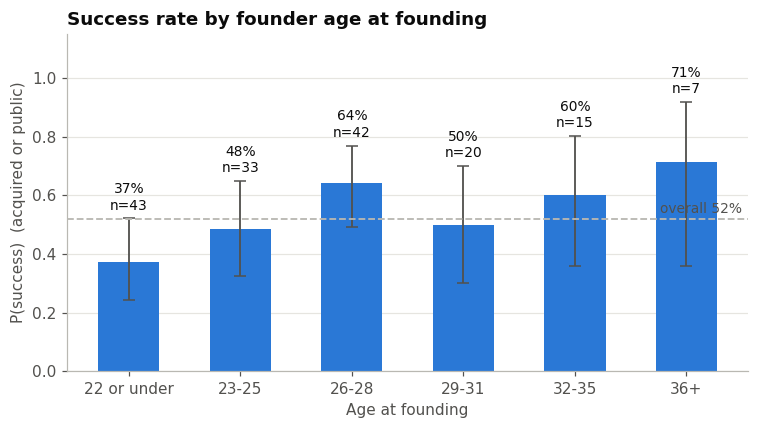

In [ ]:
AGE_BINS   = [0, 22, 25, 28, 31, 35, 100]
AGE_LABELS = ["22 or under", "23-25", "26-28", "29-31", "32-35", "36+"]
age_df = df.dropna(subset=["age", "success"]).copy()
age_df["age_band"] = pd.cut(age_df["age"], bins=AGE_BINS, labels=AGE_LABELS)

age_tbl = rate_table(age_df, "age_band", order=AGE_LABELS)
display(age_tbl.round(3))
plot_rates(age_tbl, "Success rate by founder age at founding", "Age at founding",
           baseline=age_df["success"].mean())

**1b. Model:** logistic regression with age and age squared (lets the effect rise then fall), then the same model with controls. Age is centered so the two terms are less correlated.

In [ ]:
m_df = df.dropna(subset=["age", "success", "founding_year_c"]).copy()
m_df["age_c"] = m_df["age"] - m_df["age"].mean()

m1 = fit_glm("success ~ age_c + I(age_c**2)", m_df)
print(m1.summary())
display(odds_ratios(m1))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                  160
Model:                            GLM   Df Residuals:                      157
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -107.12
Date:                Thu, 12 Nov 2026   Deviance:                       214.25
Time:                        00:31:13   Pearson chi2:                     160.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.04480
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.1728      0.218      0.792

,odds_ratio,ci_low,ci_high,p_value
Intercept,1.189,0.775,1.823,0.428
age_c,1.102,1.010,1.204,0.030
I(age_c ** 2),0.997,0.993,1.001,0.158


In [ ]:
m2 = fit_glm("success ~ age_c + I(age_c**2) + founding_year_c + C(industry_grp)", m_df)
print(m2.summary())
display(odds_ratios(m2))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                  160
Model:                            GLM   Df Residuals:                      154
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -101.26
Date:                Thu, 12 Nov 2026   Deviance:                       202.53
Time:                        00:31:13   Pearson chi2:                     162.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1123
Covariance Type:              cluster                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

,odds_ratio,ci_low,ci_high,p_value
Intercept,0.090,0.008,0.993,0.049
C(industry_grp)[T.Other],14.690,1.309,164.793,0.029
C(industry_grp)[T.Software],3.931,0.197,78.378,0.370
age_c,1.126,1.026,1.236,0.012
I(age_c ** 2),0.996,0.992,1.000,0.063
founding_year_c,0.944,0.789,1.131,0.534


**1c. Predicted P(success) by age from model 1, with a 95% confidence band.**

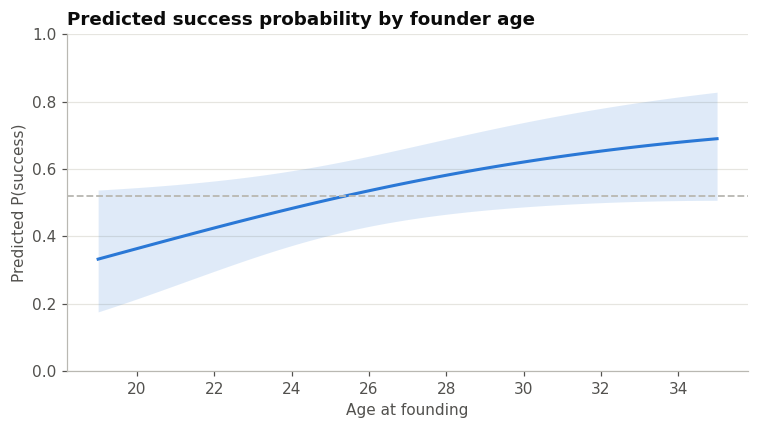

In [ ]:
grid_ages = np.linspace(m_df["age"].quantile(0.05), m_df["age"].quantile(0.95), 80)
grid = pd.DataFrame({"age_c": grid_ages - m_df["age"].mean()})
pred = m1.get_prediction(grid).summary_frame()

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(grid_ages, pred["mean_ci_lower"], pred["mean_ci_upper"], color=BLUE, alpha=0.15, lw=0)
ax.plot(grid_ages, pred["mean"], color=BLUE, lw=2)
ax.axhline(m_df["success"].mean(), color=GRAY, ls="--", lw=1.2)
ax.set_ylim(0, 1); ax.set_xlabel("Age at founding"); ax.set_ylabel("Predicted P(success)")
ax.set_title("Predicted success probability by founder age")
plt.tight_layout(); plt.show()

## 2. P(success | went to an Ivy League school)
Only founders whose education we actually know are compared. Founders with no education info are not 'non-Ivy', they are unknown, so they are excluded.

,successes,n,p_success,ci_low,ci_high
ivy_group,,,,,
Ivy League,10.0,28,0.357,0.207,0.542
Other schools,139.0,261,0.533,0.472,0.592


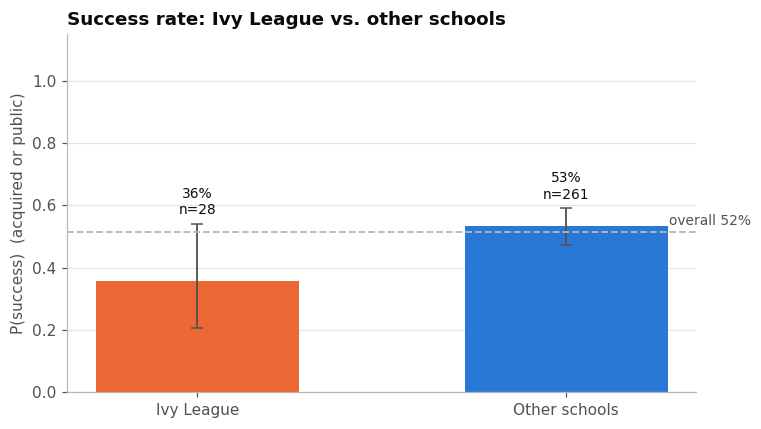

success        1.0  0.0
ivy_group              
Ivy League      10   18
Other schools  139  122 
Fisher exact test: odds ratio = 0.49, p = 0.110


In [ ]:
ivy_df = df[df["edu_known"] & df["success"].notna()].copy()
ivy_df["ivy_group"] = np.where(ivy_df["ivy"], "Ivy League", "Other schools")

ivy_tbl = rate_table(ivy_df, "ivy_group", order=["Ivy League", "Other schools"])
display(ivy_tbl.round(3))
plot_rates(ivy_tbl, "Success rate: Ivy League vs. other schools", "",
           baseline=ivy_df["success"].mean(), colors=[ORANGE, BLUE])

ct = pd.crosstab(ivy_df["ivy_group"], ivy_df["success"])
ct = ct.reindex(index=["Ivy League", "Other schools"], columns=[1.0, 0.0])   # columns: success, failure
odds, p_fisher = stats.fisher_exact(ct.values)   # odds ratio of SUCCESS, Ivy vs other
print(ct, f"\nFisher exact test: odds ratio = {odds:.2f}, p = {p_fisher:.3f}")

In [ ]:
ivy_m = ivy_df.dropna(subset=["founding_year_c"]).copy()
ivy_m["ivy_int"] = ivy_m["ivy"].astype(int)

mi1 = fit_glm("success ~ ivy_int", ivy_m)
mi2 = fit_glm("success ~ ivy_int + founding_year_c + C(industry_grp)", ivy_m)
print(mi2.summary())
display(odds_ratios(mi1).loc[["ivy_int"]].rename(index={"ivy_int": "ivy (no controls)"}))
display(odds_ratios(mi2).loc[["ivy_int"]].rename(index={"ivy_int": "ivy (+ founding year, industry)"}))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                  239
Model:                            GLM   Df Residuals:                      234
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -154.57
Date:                Thu, 12 Nov 2026   Deviance:                       309.14
Time:                        00:31:13   Pearson chi2:                     238.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.08825
Covariance Type:              cluster                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

,odds_ratio,ci_low,ci_high,p_value
ivy (no controls),0.503,0.188,1.342,0.17


,odds_ratio,ci_low,ci_high,p_value
"ivy (+ founding year, industry)",0.455,0.168,1.235,0.122


## 3. Master's vs. bachelor's only (and PhD, dropouts)

,successes,n,p_success,ci_low,ci_high
degree_level,,,,,
bachelors_only,122.0,235,0.519,0.455,0.582
masters,16.0,29,0.552,0.375,0.716
phd,9.0,16,0.562,0.332,0.769
dropout,2.0,9,0.222,0.063,0.547


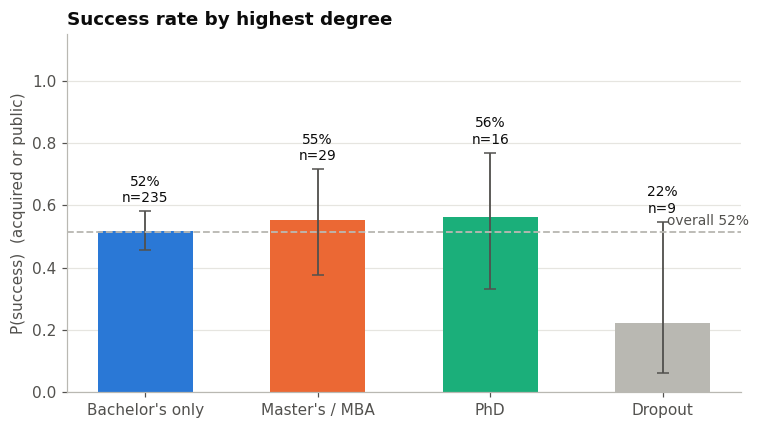

success         0.0  1.0
degree_level            
bachelors_only  113  122
dropout           7    2
masters          13   16
phd               7    9 
Chi-square test across degree levels: chi2 = 3.41, dof = 3, p = 0.333


In [ ]:
DEG_ORDER  = ["bachelors_only", "masters", "phd", "dropout"]
DEG_LABELS = ["Bachelor's only", "Master's / MBA", "PhD", "Dropout"]
deg_df = df[df["degree_level"].notna() & df["success"].notna()].copy()

deg_tbl = rate_table(deg_df, "degree_level", order=DEG_ORDER).dropna(how="all")
display(deg_tbl.round(3))
labels = [DEG_LABELS[DEG_ORDER.index(i)] for i in deg_tbl.index]
plot_rates(deg_tbl, "Success rate by highest degree", "", baseline=deg_df["success"].mean(),
           colors=[BLUE, ORANGE, "#1baf7a", GRAY][:len(deg_tbl)], labels=labels)

ct = pd.crosstab(deg_df["degree_level"], deg_df["success"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct.values)
print(ct, f"\nChi-square test across degree levels: chi2 = {chi2:.2f}, dof = {dof}, p = {p_chi:.3f}")

In [ ]:
deg_m = deg_df.dropna(subset=["founding_year_c"]).copy()
md1 = fit_glm("success ~ C(degree_level, Treatment('bachelors_only'))", deg_m)
md2 = fit_glm("success ~ C(degree_level, Treatment('bachelors_only')) + founding_year_c + C(industry_grp)", deg_m)
print(md2.summary())
display(odds_ratios(md1))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                  239
Model:                            GLM   Df Residuals:                      232
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -153.99
Date:                Thu, 12 Nov 2026   Deviance:                       307.99
Time:                        00:31:13   Pearson chi2:                     240.
No. Iterations:                     5   Pseudo R-squ. (CS):            0.09264
Covariance Type:              cluster                                         
                                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

,odds_ratio,ci_low,ci_high,p_value
Intercept,1.054,0.705,1.574,0.798
"C(degree_level, Treatment('bachelors_only'))[T.dropout]",0.271,0.051,1.429,0.124
"C(degree_level, Treatment('bachelors_only'))[T.masters]",1.186,0.504,2.791,0.696
"C(degree_level, Treatment('bachelors_only'))[T.phd]",1.329,0.301,5.855,0.707


## 4. Bonus: success by YC batch
Useful if "batch" in the professor's note meant the YC batch. Read with care: older batches have had more time to resolve, so recent batches look different partly because outcomes are not decided yet.

,successes,n,p_success,ci_low,ci_high
batch_year,,,,,
2005,8.0,9,0.889,0.565,0.980
2006,5.0,18,0.278,0.125,0.509
2007,32.0,48,0.667,0.525,0.783
2008,16.0,52,0.308,0.199,0.443
2009,28.0,53,0.528,0.397,0.656
2010,56.0,82,0.683,0.576,0.774
2011,81.0,131,0.618,0.533,0.697
2012,94.0,183,0.514,0.442,0.585
2013,48.0,94,0.511,0.411,0.609


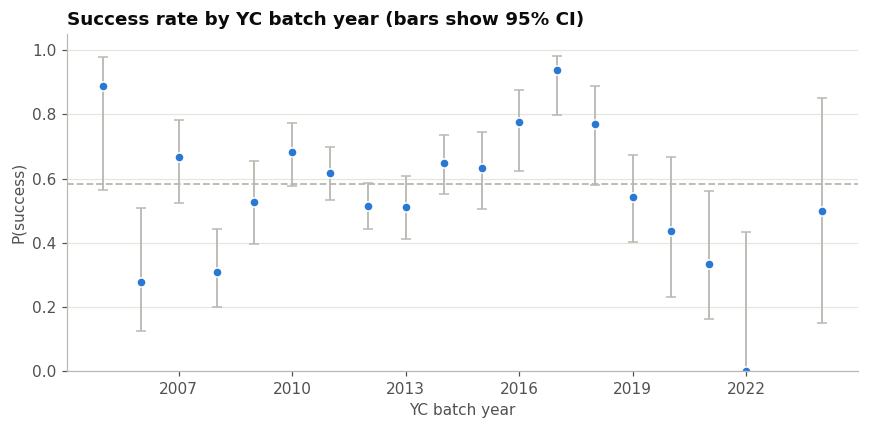

,successes,n,p_success,ci_low,ci_high
batch_season,,,,,
W,284.0,468,0.607,0.562,0.650
S,300.0,530,0.566,0.524,0.608


In [ ]:
b_df = df.dropna(subset=["batch_year", "success"]).copy()
b_df["batch_year"] = b_df["batch_year"].astype(int)

year_tbl = rate_table(b_df, "batch_year")
display(year_tbl.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(year_tbl.index, year_tbl["p_success"],
            yerr=[year_tbl["p_success"] - year_tbl["ci_low"], year_tbl["ci_high"] - year_tbl["p_success"]],
            fmt="o", color=BLUE, ecolor=GRAY, elinewidth=1.2, capsize=3, ms=6, mfc=BLUE, mec="white")
ax.axhline(b_df["success"].mean(), color=GRAY, ls="--", lw=1.2)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylim(0, 1.05); ax.set_xlabel("YC batch year"); ax.set_ylabel("P(success)")
ax.set_title("Success rate by YC batch year (bars show 95% CI)")
plt.tight_layout(); plt.show()

season_tbl = rate_table(b_df[b_df["batch_season"].isin(["W", "S"])], "batch_season", order=["W", "S"])
display(season_tbl.round(3))

In [ ]:
import pandas as pd
x = pd.read_excel("founders_linkedin_filled_final_with_kaggle.xlsx", sheet_name=0)
x["source"] = x["status_confidence"].notna().map({True: "kaggle", False: "original"})
x["success"] = x["current_status"].map({"acquired": 1, "public": 1, "inactive": 0})
x["by"] = pd.to_numeric(x["batch"].astype(str).str.extract(r"(\d{2,4})$")[0], errors="coerce")
x["by"] = x["by"].where(x["by"] > 100, 2000 + x["by"])
x["season"] = x["batch"].astype(str).str[0]
r = x.dropna(subset=["success", "by"])
print(r.groupby("source")["success"].agg(rate="mean", n="count").round(3))
print(r[r.source == "original"].groupby("season")["success"].agg(rate="mean", n="count").round(3).loc[["W", "S"]])
print(r.groupby(["by", "source"])["success"].agg(rate="mean", n="count").round(2).unstack("source"))

           rate    n
source              
kaggle    0.831  136
original  0.544  883
         rate    n
season            
W       0.570  381
S       0.528  481
         rate               n         
source kaggle original kaggle original
by                                    
2005.0    NaN     0.89    NaN      9.0
2006.0    NaN     0.28    NaN     18.0
2007.0    NaN     0.67    NaN     48.0
2008.0    NaN     0.31    NaN     52.0
2009.0    NaN     0.53    NaN     53.0
2010.0    NaN     0.68    NaN     82.0
2011.0    NaN     0.62    NaN    131.0
2012.0   1.00     0.51    3.0    180.0
2013.0    NaN     0.51    NaN     94.0
2014.0   0.89     0.63    9.0     91.0
2015.0   0.92     0.44   24.0     36.0
2016.0   0.93     0.30   30.0     10.0
2017.0   0.94     0.93   18.0     14.0
2018.0   0.88     0.56   17.0      9.0
2019.0   0.71     0.30   28.0     20.0
2020.0   0.00     0.54    3.0     13.0
2021.0   0.00     0.43    4.0     14.0
2022.0    NaN     0.00    NaN      5.0
2024.0    NaN     0.5

**4b. Original vs Kaggle founders.** If the two sources show very different success rates in the same batch year, the Kaggle statuses (mostly checked against the YC badge only) may be biased toward 'active'. Compare before pooling.

In [ ]:
src_tbl = b_df.groupby(["batch_year", "source"])["success"].agg(p_success="mean", n="count").unstack("source").round(3)
display(src_tbl)

p_success               n         
source        kaggle original kaggle original
batch_year                                   
2005             NaN    0.889    NaN      9.0
2006             NaN    0.278    NaN     18.0
2007             NaN    0.667    NaN     48.0
2008             NaN    0.308    NaN     52.0
2009             NaN    0.528    NaN     53.0
2010             NaN    0.683    NaN     82.0
2011             NaN    0.618    NaN    131.0
2012           1.000    0.506    3.0    180.0
2013             NaN    0.511    NaN     94.0
2014           0.889    0.626    9.0     91.0
2015           0.917    0.444   24.0     36.0
2016           0.933    0.300   30.0     10.0
2017           0.944    0.929   18.0     14.0
2018           0.882    0.556   17.0      9.0
2019           0.714    0.300   28.0     20.0
2020           0.000    0.538    3.0     13.0
2021           0.000    0.429    4.0     14.0
2022             NaN    0.000    NaN      5.0
2024             NaN    0.500    NaN      4.0

## Read before you report any number
- **Censoring.** Companies still `active` are excluded, so the success rate here is among resolved companies only, not all companies.
- **What "success" means.** `acquired` includes small acqui-hires. Try moving `active` into success, or splitting `public` from `acquired`, as a sensitivity check.
- **Small samples.** Age is known for only part of the rows, and the Ivy and master's groups are small. Report the confidence intervals, not just the point estimates.
- **Not independent rows.** Founders at the same company share an outcome, so the models cluster standard errors by company. Descriptive rates above still count each founder as a row.
- **Keyword-based flags.** Ivy and master's come from text matching. Report that you audited them.
- **Associations, not causes.** These are P(success | X) results. To say age causes success you need the DAG, adjustment set and matching from the main design, not just these models.
- **Kaggle statuses are weaker.** Most were checked against the YC badge only, which can be stale, and the Kaggle file has no failed companies. A missed shutdown leaves a company marked 'active', so it is excluded instead of counted as a failure, which makes failures look rarer than they are. Run once with `USE_SOURCES = ("original", "kaggle")` and once with `("original",)` and report both. (`DROP_LOW_CONFIDENCE` changes almost nothing, because low-confidence rows are mostly 'active' and already excluded.)
- **Serial founders.** The same person can appear in several rows. Try `CLUSTER_COL = "founder_id"` as a check on the standard errors.